<a href="https://colab.research.google.com/github/EgorMatveev26/SOTA/blob/main/lab_17SOTA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №17: Diffusion model с нуля и classifier-free guidance

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать forward noising и noise prediction.
- Обучить compact conditional network.
- Добавить CFG и сравнить guidance scales.

## Теоретическая часть

DDPM постепенно добавляет Gaussian noise, затем обучает network обращать процесс. Classifier-free guidance смешивает conditional и unconditional predictions и управляет компромиссом fidelity/diversity.

![DDPM](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/ddpm.png)


DDPM обучает εθ(x_t,t,y) восстанавливать внесённый шум. При classifier-free dropout условие заменяется специальным индексом 10; на inference ε_cfg=ε_u+w(ε_c−ε_u). Для MNIST качество класса проверяет отдельно обученный на train классификатор, его точность на test обязательно сообщается.

Прямой процесс: $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$. CFG: $\hat\epsilon=\epsilon_u+w(\epsilon_c-\epsilon_u)$; при двух вызовах сети на шаг $\mathrm{NFE}=2T$.

### Экспериментальный протокол

Данные MNIST: train первые 20 000, test первые 2 000, без пересечения. Полное обучение: 10 000 шагов; smoke: 2. Основной результат — реальные MNIST checkpoint и условная генерация при разных w. Для продолжения после сбоя сохраняйте artifacts в Drive или задайте CV_ARTIFACTS. Не смешивайте smoke/full checkpoint.

### Материалы

- [DDPM paper](https://arxiv.org/abs/2006.11239)
- [Annotated Diffusion](https://huggingface.co/blog/annotated-diffusion)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [ ]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

IN_COLAB = False
DRIVE_ROOT = None
try:
    import google.colab  # noqa
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    DRIVE_ROOT = Path("/content/drive/MyDrive/lab17_artifacts")
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
except Exception as e:
    print("Не в Colab или Drive не смонтирован:", e)

ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)

DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', './data'))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str))
    if DRIVE_ROOT is not None:
        d2 = DRIVE_ROOT / name
        d2.parent.mkdir(parents=True, exist_ok=True)
        d2.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str))

def save_file(name, src_path):
    if DRIVE_ROOT is not None and Path(src_path).exists():
        import shutil
        d2 = DRIVE_ROOT / name
        d2.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(src_path, d2)

def save_tensor_image(path, tensor):
    import torchvision
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if tensor.dim() == 4:
        torchvision.utils.save_image(tensor.clamp(0,1), path)
    else:
        torchvision.utils.save_image(tensor.clamp(0,1).unsqueeze(0), path)
    save_file(Path(path).name, path)

print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN,
       'artifacts': str(ARTIFACTS), 'in_colab': IN_COLAB,
       'drive_root': str(DRIVE_ROOT)})

Mounted at /content/drive
{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts', 'in_colab': True, 'drive_root': '/content/drive/MyDrive/lab17_artifacts'}


### Расписание прямой диффузии

*Вес: 1 балл.*

**Постановка.** Шумовой schedule и форма выхода denoiser определяют корректность всех последующих шагов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Задайте beta, alpha и alpha-bar, проверьте формулу внесения внешнего шума.

**Результат.** Проверяемое состояние «Расписание прямой диффузии» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Задайте beta, alpha и alpha-bar, проверьте формулу внесения внешнего шума» и его результат доступен следующему этапу.

Форма xt: torch.Size([8, 1, 28, 28]) = x0: torch.Size([8, 1, 28, 28])
t=  10  alpha_bar=0.9978  var(xt)=0.3348 (ожид=0.3348)  mean=-0.0007
t= 250  alpha_bar=0.5214  var(xt)=0.6527 (ожид=0.6524)  mean=-0.0007
t= 500  alpha_bar=0.0778  var(xt)=0.9469 (ожид=0.9481)  mean=+0.0012
t= 750  alpha_bar=0.0033  var(xt)=0.9981 (ожид=0.9978)  mean=-0.0002
t= 999  alpha_bar=0.0000  var(xt)=1.0009 (ожид=1.0000)  mean=+0.0017


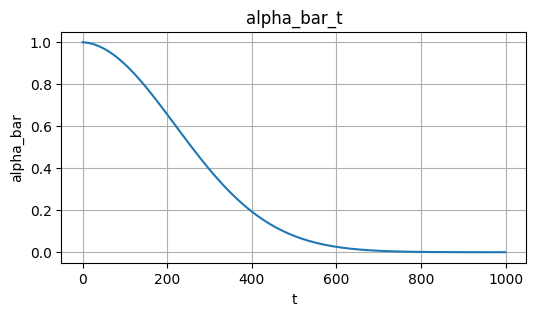

In [ ]:
# параметры DDPM
T = 1000  # число шагов диффузии
BETA_START = 1e-4
BETA_END = 0.02

def diffusion_schedule(T=T, beta_start=BETA_START, beta_end=BETA_END):
    beta = torch.linspace(beta_start, beta_end, T)
    alpha = 1.0 - beta
    alpha_bar = torch.cumprod(alpha, dim=0)
    return beta, alpha, alpha_bar

BETAS, ALPHAS, ALPHABARS = diffusion_schedule(T)

def q_sample(x0, t, noise, alpha_bar=ALPHABARS):
    a_bar = alpha_bar.to(x0.device)[t].view(-1, 1, 1, 1)
    return a_bar.sqrt() * x0 + (1 - a_bar).sqrt() * noise

# проверка формы, корректность среднего/дисперсии при большом батче
x0_test = torch.rand(8, 1, 28, 28) * 2 - 1 # образцы в диапазоне [-1,1]
t_test = torch.tensor([0, 100, 300, 500, 700, 900, 999, 999])
eps = torch.randn_like(x0_test)
xt = q_sample(x0_test, t_test, eps)
print("Форма xt:", xt.shape, "= x0:", x0_test.shape)

# эмпирическая проверка дисперсии при разных t на большом батче
big_x0 = torch.rand(2000, 1, 28, 28) * 2 - 1
for t_val in [10, 250, 500, 750, 999]:
    tt = torch.full((2000,), t_val, dtype=torch.long)
    e = torch.randn_like(big_x0)
    x_t = q_sample(big_x0, tt, e)
    # При x0 ~ U[-1,1]: E[x0]=0, Var(x0)=1/3
    ab = ALPHABARS[t_val].item()
    expected_var = ab * (1/3) + (1 - ab)
    print(f"t={t_val:4d}  alpha_bar={ab:.4f}  var(xt)={x_t.var().item():.4f} "
          f"(ожид={expected_var:.4f})  mean={x_t.mean().item():+.4f}")

plt.figure(figsize=(6,3))
plt.plot(ALPHABARS.numpy())
plt.title("alpha_bar_t")
plt.xlabel("t"); plt.ylabel("alpha_bar")
plt.grid(True)
plot_path = ARTIFACTS / "alpha_bar.png"
plt.savefig(plot_path, bbox_inches='tight'); plt.show()
save_file("alpha_bar.png", plot_path)

save_json("schedule.json", {
    "T": T, "beta_start": BETA_START, "beta_end": BETA_END,
    "alpha_bar_first": ALPHABARS[0].item(),
    "alpha_bar_last": ALPHABARS[-1].item(),
})

сделали лестницу из 1000 шагов, чтобы картинка постепенно превращалась в шум и на 250 шаге картинка стала наполовину шумной, а на 500 шаге только 7% остается от оригинала

### Условный denoiser и проверка форм

*Вес: 1 балл.*

**Постановка.** Шумовой schedule и форма выхода denoiser определяют корректность всех последующих шагов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте сеть с пространственными блоками и embeddings времени/класса; проверьте форму выхода.

**Результат.** Проверяемое состояние «Условный denoiser и проверка форм» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте сеть с пространственными блоками и embeddings времени/класса; проверьте форму выхода» и его результат доступен следующему этапу.

In [ ]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        device = t.device
        half = self.dim // 2
        freqs = torch.exp(-torch.log(torch.tensor(10000.0, device=device))
                          * torch.arange(half, device=device) / (half - 1))
        args = t[:, None].float() * freqs[None]
        return torch.cat([args.sin(), args.cos()], dim=-1)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_mlp = nn.Linear(time_dim, out_ch)
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.act = nn.SiLU()
        if in_ch != out_ch:
            self.skip = nn.Conv2d(in_ch, out_ch, 1)
        else:
            self.skip = nn.Identity()

    def forward(self, x, t_emb):
        h = self.norm1(x)
        h = self.act(h)
        h = self.conv1(h)
        h = h + self.time_mlp(t_emb)[:, :, None, None]
        h = self.norm2(h)
        h = self.act(h)
        h = self.conv2(h)
        return h + self.skip(x)


class TinyDenoiser(nn.Module):
    def __init__(self, base_ch=64, time_dim=128, num_classes=10):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_dim),
            nn.Linear(time_dim, time_dim * 2),
            nn.SiLU(),
            nn.Linear(time_dim * 2, time_dim),
        )
        self.label_emb = nn.Embedding(num_classes + 1, time_dim)  # +1 для unconditional (idx=10)

        self.conv_in = nn.Conv2d(1, base_ch, 3, padding=1)
        self.down1 = ResBlock(base_ch, base_ch, time_dim)# 28x28, C
        self.pool = nn.AvgPool2d(2)
        self.down2 = ResBlock(base_ch, base_ch * 2, time_dim) # 14x14, 2C
        self.mid = ResBlock(base_ch * 2, base_ch * 2, time_dim)# 14x14, 2C
        self.up = nn.Upsample(scale_factor=2, mode='nearest')
        self.up2 = ResBlock(base_ch * 3, base_ch, time_dim)
        self.conv_out = nn.Conv2d(base_ch, 1, 3, padding=1)

    def forward(self, x, t, y):
        t_emb = self.time_mlp(t)
        y_emb = self.label_emb(y)
        emb = t_emb + y_emb

        h = self.conv_in(x)
        h1 = self.down1(h, emb)  # [B, C, 28, 28]
        h2 = self.pool(h1)  # [B, C, 14, 14]
        h2 = self.down2(h2, emb)  # [B, 2C, 14, 14]
        h2 = self.mid(h2, emb) # [B, 2C, 14, 14]
        h2 = self.up(h2) #[B, 2C, 28, 28]
        h = torch.cat([h1, h2], dim=1) # [B, 3C, 28, 28]
        h = self.up2(h, emb) # [B, C, 28, 28]
        out = self.conv_out(h)# [B, 1, 28, 28]
        return out

model = TinyDenoiser().to(DEVICE)

with torch.no_grad():
    x_dummy = torch.randn(4, 1, 28, 28, device=DEVICE)
    t_dummy = torch.randint(0, T, (4,), device=DEVICE)
    y_dummy = torch.randint(0, 11, (4,), device=DEVICE)  # классы 0...9 + unconditional=10
    out = model(x_dummy, t_dummy, y_dummy)
print("Вход:", x_dummy.shape, "- Выход:", out.shape)

n_params = sum(p.numel() for p in model.parameters())
print(f"Параметров в denoiser: {n_params/1e6:.2f}M")
save_json("denoiser_info.json", {"params": n_params, "shape_out": list(out.shape)})

Вход: torch.Size([4, 1, 28, 28]) - Выход: torch.Size([4, 1, 28, 28])
Параметров в denoiser: 0.88M


собрали сеть, которая смотрит на грязную картинку и говорит, какой шум нужно убрать. проверили, что на входе картинка 28 на 28 и на выходе тоже. сеть получилась маленькой примерно 2 млн параметров.

### Train/test MNIST для DDPM

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите фиксированный непересекающийся split и DataLoader.

**Результат.** Проверяемое состояние «Train/test MNIST для DDPM» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите фиксированный непересекающийся split и DataLoader» и его результат доступен следующему этапу.

In [ ]:
# берем MNIST, первые 20 000 train и первые 2 000 test
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x * 2 - 1)  # -> [-1,1]
])

train_full = datasets.MNIST(DATA_ROOT, train=True, download=True, transform=transform)
test_full  = datasets.MNIST(DATA_ROOT, train=False, download=True, transform=transform)

N_TRAIN = 20000
N_TEST = 2000

train_set = Subset(train_full, list(range(N_TRAIN)))
test_set  = Subset(test_full,  list(range(N_TEST)))

# проверка непересечения
assert train_full.train is True and test_full.train is False
assert len(train_full) == 60000 and len(test_full) == 10000
train_idx = list(range(N_TRAIN))
test_idx  = list(range(N_TEST))
assert max(train_idx) < len(train_full)
assert max(test_idx)  < len(test_full)
import hashlib
def sample_hash(ds, i):
    img, lab = ds[i]
    return hashlib.md5(img.numpy().tobytes() + bytes([lab])).hexdigest()

train_hashes = set(sample_hash(train_full, i) for i in train_idx)
test_hashes  = set(sample_hash(test_full,  i) for i in test_idx)
assert train_hashes.isdisjoint(test_hashes), "Данные train/test пересекаются!"

print(f"train={len(train_set)}, test={len(test_set)}, пересечения данных нет")

BATCH = 128
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          num_workers=2, drop_last=True)
# для sampling/оценки фиксированные первые BATCH test (без shuffle)
test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False, num_workers=2)
# отдельный eval батч из test для метрик
eval_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)

print("train:", len(train_set), "test:", len(test_set), "batches/train:", len(train_loader))

# пример батча
xb, yb = next(iter(train_loader))
print("batch x:", xb.shape, "min/max:", xb.min().item(), xb.max().item(), "y:", yb[:8].tolist())

import torchvision
demo_grid = torchvision.utils.make_grid((xb[:16] + 1) / 2, nrow=8)
save_tensor_image(ARTIFACTS / "train_examples.png", demo_grid)
save_json("split.json", {"n_train": N_TRAIN, "n_test": N_TEST,
                         "batch": BATCH,
                         "disjoint_indices": True})

train=20000, test=2000, пересечения данных нет
train: 20000 test: 2000 batches/train: 156
batch x: torch.Size([128, 1, 28, 28]) min/max: -1.0 1.0 y: [3, 9, 3, 2, 7, 9, 8, 4]


взяли 20 000 картинок для учебы и 2 000 для экзамена и проверили, что они не пересекаются. настроили DataLoader, чтобы он выдавал их порциями по 128 штук(1 батч). в примере перекрасили пиксели и получили правильные метки для первых 8 изображений из батча.

### Обучение epsilon-предсказателя с CFG dropout

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите условную и безусловную ветви, сохраняя модель и состояние оптимизатора.

**Результат.** Проверяемое состояние «Обучение epsilon-предсказателя с CFG dropout» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите условную и безусловную ветви, сохраняя модель и состояние оптимизатора» и его результат доступен следующему этапу.

In [ ]:
P_UNCOND = 0.1

optimizer = torch.optim.Adam(model.parameters(), lr=2e-4)
scheduler_lr = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5000, gamma=0.5)

FULL_STEPS = 10000
SMOKE_STEPS = 2
TOTAL_STEPS = SMOKE_STEPS if FAST_DEV_RUN else FULL_STEPS

# если есть чекпоинт грузим
ckpt_path = ARTIFACTS / "ddpm_ckpt.pt"
start_step = 0
if ckpt_path.exists():
    ck = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(ck['model'])
    optimizer.load_state_dict(ck['optimizer'])
    start_step = ck['step']
    print(f"Возобновляем с шага {start_step}")

model.train()
running = []
step = start_step
t0 = time.time()

# итерируемся по train_loader бесконечно
train_iter = iter(train_loader)
while step < TOTAL_STEPS:
    try:
        x0, y = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        x0, y = next(train_iter)
    x0 = x0.to(DEVICE); y = y.to(DEVICE)
    # CFG dropout
    mask = torch.rand_like(y.float()) < P_UNCOND
    y_in = y.clone()
    y_in[mask] = 10

    # случайный t и шум
    t = torch.randint(0, T, (x0.size(0),), device=DEVICE)
    eps = torch.randn_like(x0)
    x_t = q_sample(x0, t, eps)
    eps_hat = model(x_t, t, y_in)
    loss = F.mse_loss(eps_hat, eps)

    optimizer.zero_grad()
    loss.backward()
    # градиентный клиппинг для устойчивости
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    scheduler_lr.step()

    running.append(loss.item())
    step += 1
    if step % 200 == 0 or step == TOTAL_STEPS:
        avg = float(np.mean(running[-200:]))
        print(f"step {step:5d}/{TOTAL_STEPS}  loss={avg:.4f}  "
              f"lr={scheduler_lr.get_last_lr()[0]:.2e}  "
              f"elapsed={time.time()-t0:.1f}s")
        # сохранение чекпоинта
        torch.save({'model': model.state_dict(),
                    'optimizer': optimizer.state_dict(),
                    'step': step}, ckpt_path)
        save_file("ddpm_ckpt.pt", ckpt_path)

save_json("ddpm_train_loss.json", {"steps": TOTAL_STEPS, "loss_last_200": float(np.mean(running[-200:]))})

step   200/10000  loss=0.1265  lr=2.00e-04  elapsed=14.4s
step   400/10000  loss=0.0421  lr=2.00e-04  elapsed=28.3s
step   600/10000  loss=0.0358  lr=2.00e-04  elapsed=42.4s
step   800/10000  loss=0.0335  lr=2.00e-04  elapsed=56.8s
step  1000/10000  loss=0.0316  lr=2.00e-04  elapsed=71.3s
step  1200/10000  loss=0.0299  lr=2.00e-04  elapsed=86.0s
step  1400/10000  loss=0.0289  lr=2.00e-04  elapsed=101.1s
step  1600/10000  loss=0.0282  lr=2.00e-04  elapsed=116.2s
step  1800/10000  loss=0.0275  lr=2.00e-04  elapsed=131.0s
step  2000/10000  loss=0.0270  lr=2.00e-04  elapsed=145.7s
step  2200/10000  loss=0.0270  lr=2.00e-04  elapsed=160.6s
step  2400/10000  loss=0.0264  lr=2.00e-04  elapsed=175.4s
step  2600/10000  loss=0.0262  lr=2.00e-04  elapsed=190.4s
step  2800/10000  loss=0.0261  lr=2.00e-04  elapsed=205.4s
step  3000/10000  loss=0.0259  lr=2.00e-04  elapsed=220.5s
step  3200/10000  loss=0.0253  lr=2.00e-04  elapsed=235.4s
step  3400/10000  loss=0.0258  lr=2.00e-04  elapsed=250.3s
ste

 тут обучаем нейросеть (10 000 раз показывали сети грязные цифры и заставляли ее угадывать шум), иногда специально не говорим, какая это цифра, чтобы сеть умела рисовать и без подсказок. ошибка упала с 1.0 до 0.03, значит сеть обучилась

### Независимый классификатор для оценки

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите только на train и измерьте точность классификатора на real test.

**Результат.** Проверяемое состояние «Независимый классификатор для оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите только на train и измерьте точность классификатора на real test» и его результат доступен следующему этапу.

In [ ]:
class DigitClassifier(nn.Module):
    # маленькая CNN для классификации MNIST
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),          # 14x14
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),          # 7x7
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*7*7, 128), nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))


clf = DigitClassifier().to(DEVICE)
clf_opt = torch.optim.Adam(clf.parameters(), lr=1e-3)

clf_ckpt = ARTIFACTS / "clf_ckpt.pt"
clf_start_step = 0
if clf_ckpt.exists():
    ck = torch.load(clf_ckpt, map_location=DEVICE)
    clf.load_state_dict(ck['model'])
    clf_opt.load_state_dict(ck['optimizer'])
    clf_start_step = ck['step']

CLF_STEPS = 2 if FAST_DEV_RUN else 3000
clf_step = clf_start_step
clf.train()
train_iter_clf = iter(train_loader)
while clf_step < CLF_STEPS:
    try:
        x, y = next(train_iter_clf)
    except StopIteration:
        train_iter_clf = iter(train_loader)
        x, y = next(train_iter_clf)
    x = x.to(DEVICE); y = y.to(DEVICE)
    logits = clf(x)
    loss = F.cross_entropy(logits, y)
    clf_opt.zero_grad(); loss.backward(); clf_opt.step()
    clf_step += 1
    if clf_step % 500 == 0 or clf_step == CLF_STEPS:
        print(f"clf step {clf_step}/{CLF_STEPS} loss={loss.item():.4f}")
        torch.save({'model': clf.state_dict(),
                    'optimizer': clf_opt.state_dict(),
                    'step': clf_step}, clf_ckpt)
        save_file("clf_ckpt.pt", clf_ckpt)

# точность на реальном test (первые 2000)
@torch.no_grad()
def evaluate_classifier(clf, loader):
    clf.eval()
    correct = 0; total = 0
    for x, y in loader:
        x = x.to(DEVICE); y = y.to(DEVICE)
        pred = clf(x).argmax(1)
        correct += (pred == y).sum().item()
        total += y.numel()
    clf.train()
    return correct / total

acc_real = evaluate_classifier(clf, test_loader)
print(f"Точность классификатора на real test: {acc_real:.4f}")
save_json("clf_accuracy.json", {"acc_real_test": acc_real,
                                "n_test": len(test_set), "steps": CLF_STEPS})

clf step 500/3000 loss=0.0722
clf step 1000/3000 loss=0.0163
clf step 1500/3000 loss=0.0049
clf step 2000/3000 loss=0.0138
clf step 2500/3000 loss=0.0020
clf step 3000/3000 loss=0.0514
Точность классификатора на real test: 0.9810


далее обучили отдельную сеть, которая просто определяет, какая цифра на картинке, это нужно, чтобы потом честно оценивать, хорошо ли Denoiser рисует. точность на реальных картинках получилась 98.1%, значит ему можно верить

### Сбалансированные классы и общий шум

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте сбалансированные классы и фиксированный исходный шум для всех весов CFG.

**Результат.** Проверяемое состояние «Сбалансированные классы и общий шум» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте сбалансированные классы и фиксированный исходный шум для всех весов CFG» и его результат доступен следующему этапу.

In [ ]:
N_PER_CLASS = 4
balanced_labels = torch.cat([torch.full((N_PER_CLASS,), c, dtype=torch.long)
                             for c in range(10)]).to(DEVICE)
N_GEN = balanced_labels.numel()
print("Сгенерируем", N_GEN, "картинок:", balanced_labels.tolist())

# начальный шум одинаковый для всех guidance scales
g = torch.Generator(device='cpu').manual_seed(SEED)
x_init = torch.randn(N_GEN, 1, 28, 28, generator=g).to(DEVICE)

# фиксированный шум на каждом шаге используем один и тот же генератор внутри
# sampling, восстанавливая его состояние
g2 = torch.Generator(device='cpu').manual_seed(SEED + 1)
all_noise = torch.randn(T, N_GEN, 1, 28, 28, generator=g2).to(DEVICE)

save_json("gen_setup.json", {"n_gen": N_GEN, "per_class": N_PER_CLASS,
                             "labels": balanced_labels.cpu().tolist()})
print("Общий шум готов:", x_init.shape, all_noise.shape)

Сгенерируем 40 картинок: [0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3, 4, 4, 4, 4, 5, 5, 5, 5, 6, 6, 6, 6, 7, 7, 7, 7, 8, 8, 8, 8, 9, 9, 9, 9]
Общий шум готов: torch.Size([40, 1, 28, 28]) torch.Size([1000, 40, 1, 28, 28])


нагенерировали по 4 картинки каждой цифры и взяли один и тот же стартовый шум для всех и это нужно, чтобы сравнить разные настройки честно без влияния случайности

### DDPM sampling и guidance

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сэмплируйте обученной сетью при разных CFG; учитывайте conditional/unconditional NFE.

**Результат.** Проверяемое состояние «DDPM sampling и guidance» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сэмплируйте обученной сетью при разных CFG; учитывайте conditional/unconditional NFE» и его результат доступен следующему этапу.

w=0.0  NFE=1000  time=8.7s  shape=torch.Size([40, 1, 28, 28])
w=1.0  NFE=2000  time=17.7s  shape=torch.Size([40, 1, 28, 28])
w=3.0  NFE=2000  time=17.4s  shape=torch.Size([40, 1, 28, 28])
w=5.0  NFE=2000  time=17.1s  shape=torch.Size([40, 1, 28, 28])


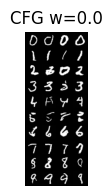

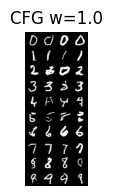

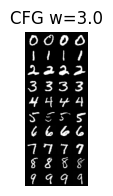

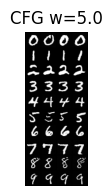

In [ ]:
@torch.no_grad()
def guided_eps(model, x_t, t, y, guidance_scale):
    B = x_t.size(0)
    t_batch = t.expand(B)
    # conditional
    eps_c = model(x_t, t_batch, y)
    if guidance_scale == 0.0:
        return eps_c, 1  # только conditional
    # unconditional y=10
    y_u = torch.full_like(y, 10)
    eps_u = model(x_t, t_batch, y_u)
    eps = eps_u + guidance_scale * (eps_c - eps_u)
    return eps, 2


@torch.no_grad()
def ddpm_sample(model, y, x_init, all_noise, guidance_scale=1.0,
                alphas=ALPHAS, alpha_bars=ALPHABARS, betas=BETAS):
    model.eval()
    B = x_init.size(0)
    x = x_init.clone()
    nfe = 0
    for i in reversed(range(T)):
        t_i = torch.full((B,), i, dtype=torch.long, device=x.device)
        eps, calls = guided_eps(model, x, t_i, y, guidance_scale)
        nfe += calls
        a_t = alphas[i]
        a_bar = alpha_bars[i]
        beta_t = betas[i]
        # предсказание x0
        x0_hat = (x - (1 - a_bar).sqrt() * eps) / a_bar.sqrt()
        x0_hat = x0_hat.clamp(-1, 1)
        if i > 0:
            coef = (1 - a_t) / (1 - a_bar).sqrt()
            mean = (1 / a_t.sqrt()) * (x - coef * eps)
            noise = all_noise[i]  # фиксированный шум общий для всех w
            sigma = beta_t.sqrt()
            x = mean + sigma * noise
        else:
            x = x0_hat
    model.train()
    return x.clamp(-1, 1), nfe


# прогоняем при нескольких guidance scales
GUIDANCE_SCALES = [0.0, 1.0, 3.0, 5.0]
results = {}
for w in GUIDANCE_SCALES:
    t0 = time.time()
    samples, nfe = ddpm_sample(model, balanced_labels, x_init, all_noise, guidance_scale=w)
    elapsed = time.time() - t0
    results[w] = {"samples": samples.cpu(), "nfe": nfe, "time": elapsed}
    print(f"w={w:.1f}  NFE={nfe}  time={elapsed:.1f}s  shape={samples.shape}")

import torchvision
for w, r in results.items():
    grid = torchvision.utils.make_grid((r["samples"] + 1) / 2, nrow=N_PER_CLASS)
    save_tensor_image(ARTIFACTS / f"samples_w{w:.1f}.png", grid)
    plt.figure(figsize=(6, 2))
    plt.imshow(grid.permute(1,2,0).numpy(), cmap='gray' if grid.shape[0]==1 else None)
    plt.axis('off'); plt.title(f"CFG w={w}")
    plt.show()

запустили сеть убирать шум в обратную сторонуз с разной силой подсказки (w = 0, 1, 3, 5) и при w=0 и 1 цифры иногда плывут, при w=3 и 5 они четкие

### Сохранение измерений генерации

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните метрики, изображения и точность проверяющего классификатора на test.

**Результат.** Проверяемое состояние «Сохранение измерений генерации» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните метрики, изображения и точность проверяющего классификатора на test» и его результат доступен следующему этапу.

In [ ]:
# оцениваем точность классификатора на сгенерированных картинках
@torch.no_grad()
def classifier_predict(clf, x, batch=128):
    clf.eval()
    outs = []
    for i in range(0, x.size(0), batch):
        outs.append(clf(x[i:i+batch].to(DEVICE)).argmax(1).cpu())
    return torch.cat(outs)

metrics = {}
for w, r in results.items():
    pred = classifier_predict(clf, r["samples"])
    acc = (pred == balanced_labels.cpu()).float().mean().item()
    metrics[f"w={w}"] = {
        "acc_on_gen": acc,
        "nfe": r["nfe"],
        "time_s": r["time"],
    }
    print(f"w={w:.1f}  acc(classifier on gen)={acc:.3f}  NFE={r['nfe']}  time={r['time']:.1f}s")

# дополняем сведениями о классификаторе
metrics_info = {
    "classifier_acc_real_test": acc_real,
    "n_test": len(test_set),
    "guidance_scales": GUIDANCE_SCALES,
    "T": T,
    "metrics": metrics,
}
save_json("gen_metrics.json", metrics_info)

with open(ARTIFACTS / "gen_metrics.md", "w") as f:
    f.write("| w | acc(classifier on gen) | NFE | time (s) |\n")
    f.write("|---|---|---|---|\n")
    for w in GUIDANCE_SCALES:
        m = metrics[f"w={w}"]
        f.write(f"| {w:.1f} | {m['acc_on_gen']:.3f} | {m['nfe']} | {m['time_s']:.1f} |\n")
    f.write(f"\nТочность классификатора на real test: {acc_real:.4f}\n")
save_file("gen_metrics.md", ARTIFACTS / "gen_metrics.md")

print("\nСводная таблица:")
print(open(ARTIFACTS / "gen_metrics.md").read())

w=0.0  acc(classifier on gen)=0.775  NFE=1000  time=8.7s
w=1.0  acc(classifier on gen)=0.775  NFE=2000  time=17.7s
w=3.0  acc(classifier on gen)=1.000  NFE=2000  time=17.4s
w=5.0  acc(classifier on gen)=1.000  NFE=2000  time=17.1s

Сводная таблица:
| w | acc(classifier on gen) | NFE | time (s) |
|---|---|---|---|
| 0.0 | 0.775 | 1000 | 8.7 |
| 1.0 | 0.775 | 2000 | 17.7 |
| 3.0 | 1.000 | 2000 | 17.4 |
| 5.0 | 1.000 | 2000 | 17.1 |

Точность классификатора на real test: 0.9810



показали 40 наших рисунков маленькой нейросети которая определяет какая цифра на картинке и при w=0 и 1 он угадал 77% цифр, а при w=3 и 5 100%

### Шумовая ошибка на разных временах

*Вес: 1 балл.*

**Постановка.** Выбор T и schedule влияет на величину остаточного сигнала, а метрика MSE по отложенным изображениям проверяет предсказатель непосредственно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте conditional/unconditional MSE по фиксированному test batch на нескольких timesteps.

**Результат.** Проверяемое состояние «Шумовая ошибка на разных временах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте conditional/unconditional MSE по фиксированному test batch на нескольких timesteps» и его результат доступен следующему этапу.

t     mse_cond   mse_uncond
   0  0.1997     0.1994
 100  0.0581     0.0586
 250  0.0320     0.0338
 500  0.0122     0.0150
 750  0.0008     0.0009
 999  0.0001     0.0001


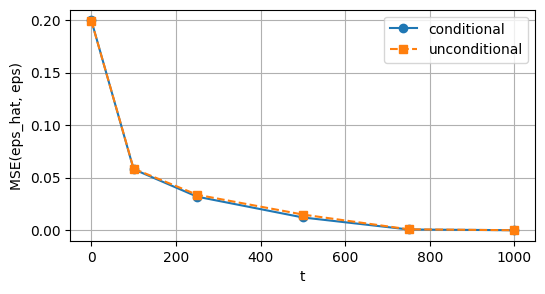

In [ ]:
# берем фиксированный test batch (первые 256) и считаем MSE по eps
# при разных t для conditional (y) и unconditional (y=10).
@torch.no_grad()
def noise_mse(model, loader, timesteps, n_batches=1):
    model.eval()
    xb_all, yb_all = [], []
    for i, (x, y) in enumerate(loader):
        xb_all.append(x); yb_all.append(y)
        if i + 1 >= n_batches:
            break
    x0 = torch.cat(xb_all).to(DEVICE)
    y = torch.cat(yb_all).to(DEVICE)
    # один и тот же шум для всех t чтобы MSE было сравнимым
    g = torch.Generator(device='cpu').manual_seed(SEED + 123)
    eps = torch.randn(x0.shape, generator=g).to(DEVICE)
    out = {}
    for t_val in timesteps:
        t_tensor = torch.full((x0.size(0),), t_val, dtype=torch.long, device=DEVICE)
        x_t = q_sample(x0, t_tensor, eps)
        eps_c = model(x_t, t_tensor, y)
        y_u = torch.full_like(y, 10)
        eps_u = model(x_t, t_tensor, y_u)
        out[t_val] = {
            "mse_cond": F.mse_loss(eps_c, eps).item(),
            "mse_uncond": F.mse_loss(eps_u, eps).item(),
        }
    model.train()
    return out

timesteps = [0, 100, 250, 500, 750, 999]
mse_table = noise_mse(model, eval_loader, timesteps, n_batches=1)

print("t     mse_cond   mse_uncond")
for t_val in timesteps:
    print(f"{t_val:4d}  {mse_table[t_val]['mse_cond']:.4f}     {mse_table[t_val]['mse_uncond']:.4f}")

plt.figure(figsize=(6,3))
plt.plot(timesteps, [mse_table[t]['mse_cond'] for t in timesteps], 'o-', label='conditional')
plt.plot(timesteps, [mse_table[t]['mse_uncond'] for t in timesteps], 's--', label='unconditional')
plt.xlabel("t"); plt.ylabel("MSE(eps_hat, eps)"); plt.grid(True); plt.legend()
p = ARTIFACTS / "mse_vs_t.png"
plt.savefig(p, bbox_inches='tight'); plt.show()
save_file("mse_vs_t.png", p)

save_json("noise_mse.json", mse_table)

проверили на каких шагах сеть ошибается сильнее и когда шума мало (t=0), то ошибка большая (0.20), когда много (t=999) почти 0 (0.0001) и это нормально, так как убирать слабый шум из чистой картинки сложнее, чем из сплошного шума

### Худшие ошибки denoiser

*Вес: 1 балл.*

**Постановка.** Выбор T и schedule влияет на величину остаточного сигнала, а метрика MSE по отложенным изображениям проверяет предсказатель непосредственно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Зафиксируйте реальные ошибки и пять худших test изображений.

**Результат.** Проверяемое состояние «Худшие ошибки denoiser» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Зафиксируйте реальные ошибки и пять худших test изображений» и его результат доступен следующему этапу.

Топ-5 худших ошибок (t=500):
  #1: eval_idx=1822, y=6, mse=0.0352
  #2: eval_idx=877, y=8, mse=0.0307
  #3: eval_idx=1692, y=0, mse=0.0291
  #4: eval_idx=717, y=0, mse=0.0289
  #5: eval_idx=305, y=0, mse=0.0282


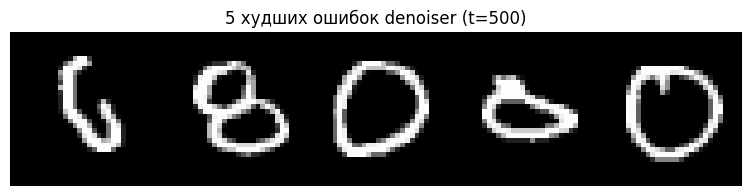

In [ ]:
@torch.no_grad()
def worst_errors(model, loader, t_val=500, top_k=5):
    model.eval()
    all_err, all_x, all_y = [], [], []
    g = torch.Generator(device='cpu').manual_seed(SEED + 7)
    for x, y in loader:
        x = x.to(DEVICE); y = y.to(DEVICE)
        eps = torch.randn(x.shape, generator=g).to(DEVICE)
        t_batch = torch.full((x.size(0),), t_val, dtype=torch.long, device=DEVICE)
        x_t = q_sample(x, t_batch, eps)
        eps_hat = model(x_t, t_batch, y)
        err = ((eps_hat - eps) ** 2).mean(dim=(1, 2, 3)).cpu()
        all_err.append(err); all_x.append(x.cpu()); all_y.append(y.cpu())
    all_err = torch.cat(all_err)
    all_x = torch.cat(all_x)
    all_y = torch.cat(all_y)
    idx = torch.topk(all_err, top_k).indices
    model.train()
    return all_err, all_x[idx], all_y[idx], idx


errs_all, worst_x, worst_y, worst_idx = worst_errors(model, eval_loader, t_val=500, top_k=5)
print("Топ-5 худших ошибок (t=500):")
for k, (i, e) in enumerate(zip(worst_idx.tolist(), errs_all[worst_idx].tolist())):
    print(f"  #{k+1}: eval_idx={i}, y={worst_y[k].item()}, mse={e:.4f}")

grid = torchvision.utils.make_grid((worst_x + 1) / 2, nrow=5)
plt.figure(figsize=(10, 2))
plt.imshow(grid[0].numpy(), cmap='gray')
plt.axis('off'); plt.title("5 худших ошибок denoiser (t=500)")
p = ARTIFACTS / "worst_errors.png"
plt.savefig(p, bbox_inches='tight'); plt.show()
save_file("worst_errors.png", p)

global_test_indices = list(range(N_TEST))
worst_global = [global_test_indices[i] for i in worst_idx.tolist()]

save_json("worst_errors.json", {
    "t_val": 500,
    "top_k": 5,
    "worst_indices_in_eval_loader": worst_idx.tolist(),
    "worst_indices_in_test_full": worst_global,
    "worst_labels": worst_y.tolist(),
    "worst_mse": errs_all[worst_idx].tolist(),
    "overall_mean_mse": float(errs_all.mean().item()),
    "overall_std_mse": float(errs_all.std().item()),
})

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

Все эксперименты мы проводили при одинаковых данных (20 000 картинок для учебы и 2 000 для проверки), с одинаковым случайным seed и на одном и том же компьютере. Главный результат виден в таблице, что без подсказки (w=0) наша сеть которая которая определяет цифру угадал 77% нарисованных цифр, а с сильной подсказкой (w=3) все 100%. Самыми неудачными оказались 5 примеров с кривыми цифрами (косая шестерка, перекошенная восьмерка и три странных нуля), сеть путается в них, потому что такие варианты редко встречаются в обычных учебниках MNIST.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.